# Detph and Velocity GT analysis

Overlay GT depth and velocity

Note: use env seg_clone_2311

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from mmengine.dataset import Compose

from tqdm import tqdm

from mmseg.datasets.sys100_ppp_heatmap_dataset import Sys100PPPHeatmapDataset
from mmseg.datasets.transforms.sys100_ppp_transforms import LoadSys100Sample, BuildPPPHeatmap

In [51]:
SYS100_ROOT = '/home/lorenz-linux/repositories/aumovio_data/aumovio_sys100_data'

In [ ]:
pipeline = Compose([
    LoadSys100Sample(
        sys100_root=SYS100_ROOT,
        out_img_size=(544, 1792),
        undistort=True,
        fovs=(105, 48.4),
    ),
    BuildPPPHeatmap(
        thres=0.05,
        clip_depth=(0.0, 150.0),
        clip_vel=(-10.0, 10.0),
    ),
])

0 valid, 0 error files: 100%|██████████| 1/1 [00:00<00:00, 422.43it/s]


In [58]:
dataset = Sys100PPPHeatmapDataset(
    sys100_root=SYS100_ROOT,
)

print('Number of frames:', len(dataset))


0 valid, 0 error files: 100%|██████████| 1/1 [00:00<00:00, 301.27it/s]


Number of frames: 187


In [59]:
start = 2
num_frames = 1

In [60]:
sample0 = pipeline(dataset[0])
H, W = sample0["gt_seg_map"].shape[:2]
print('H, W', H, W)

count_map = np.zeros((H, W), dtype=np.float32)
depth_sum = np.zeros((H, W), dtype=np.float32)
vel_sum   = np.zeros((H, W), dtype=np.float32)

for i in range(start, start + num_frames):
    res = pipeline(dataset[i])
    gt = res["gt_seg_map"]  # (H,W,3)

    mask = gt[..., 0] > 0
    depth = gt[..., 1]
    vel   = gt[..., 2]

    count_map[mask] += 1
    depth_sum[mask] += depth[mask]
    vel_sum[mask]   += vel[mask]


H, W 544 1792


In [61]:
# compute the per-pixel mean of depth and velocity over time (while avoiding division-by-zero)
eps = 1e-6
mean_depth = depth_sum / (count_map + eps)
mean_vel   = vel_sum   / (count_map + eps)


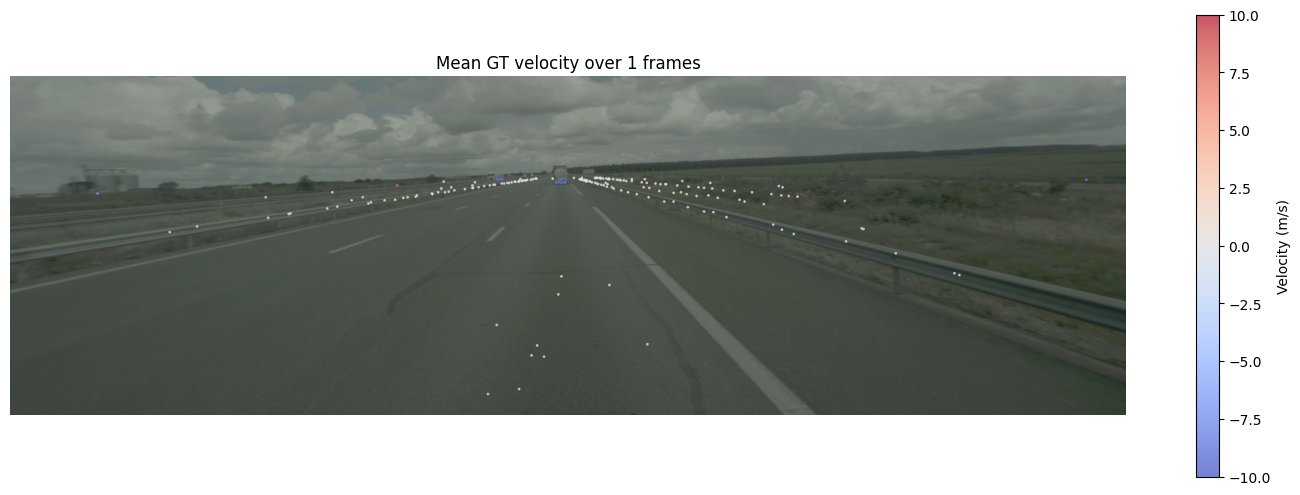

In [62]:
img = res["img"]  # uint8 HWC

plt.figure(figsize=(18, 6))
plt.imshow(img)

# --- extract points ---
mask = np.isfinite(mean_vel) & (mean_vel != 0)
ys, xs = np.where(mask)
vals = mean_vel[ys, xs]

# --- scatter as big dots ---
plt.scatter(
    xs,
    ys,
    c=vals,
    cmap="coolwarm",
    vmin=-10,
    vmax=10,
    s=1,
    alpha=0.7,
)

plt.colorbar(label="Velocity (m/s)")
plt.title(f"Mean GT velocity over {num_frames} frames")
plt.axis("off")
plt.show()

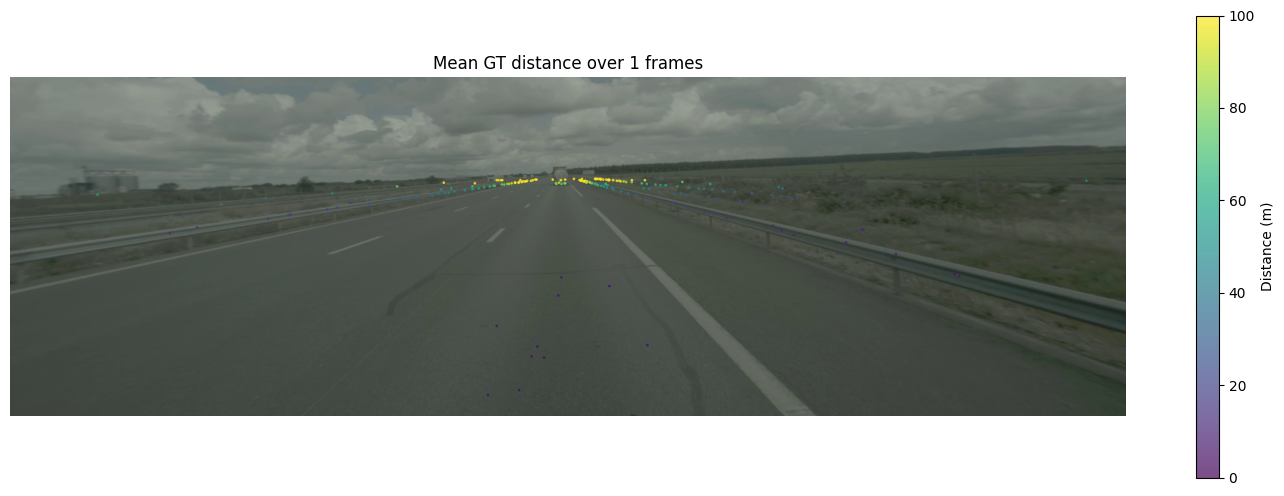

In [63]:
img = res["img"]  # uint8 HWC

plt.figure(figsize=(18, 6))
plt.imshow(img)

# --- extract points ---
mask = np.isfinite(mean_depth) & (mean_depth > 0)
ys, xs = np.where(mask)
vals = mean_depth[ys, xs]

# --- scatter distance ---
plt.scatter(
    xs,
    ys,
    c=vals,
    cmap="viridis",
    vmin=0,
    vmax=100,   # adjust to your radar range
    s=1,
    alpha=0.7,
)

plt.colorbar(label="Distance (m)")
plt.title(f"Mean GT distance over {num_frames} frames")
plt.axis("off")
plt.show()

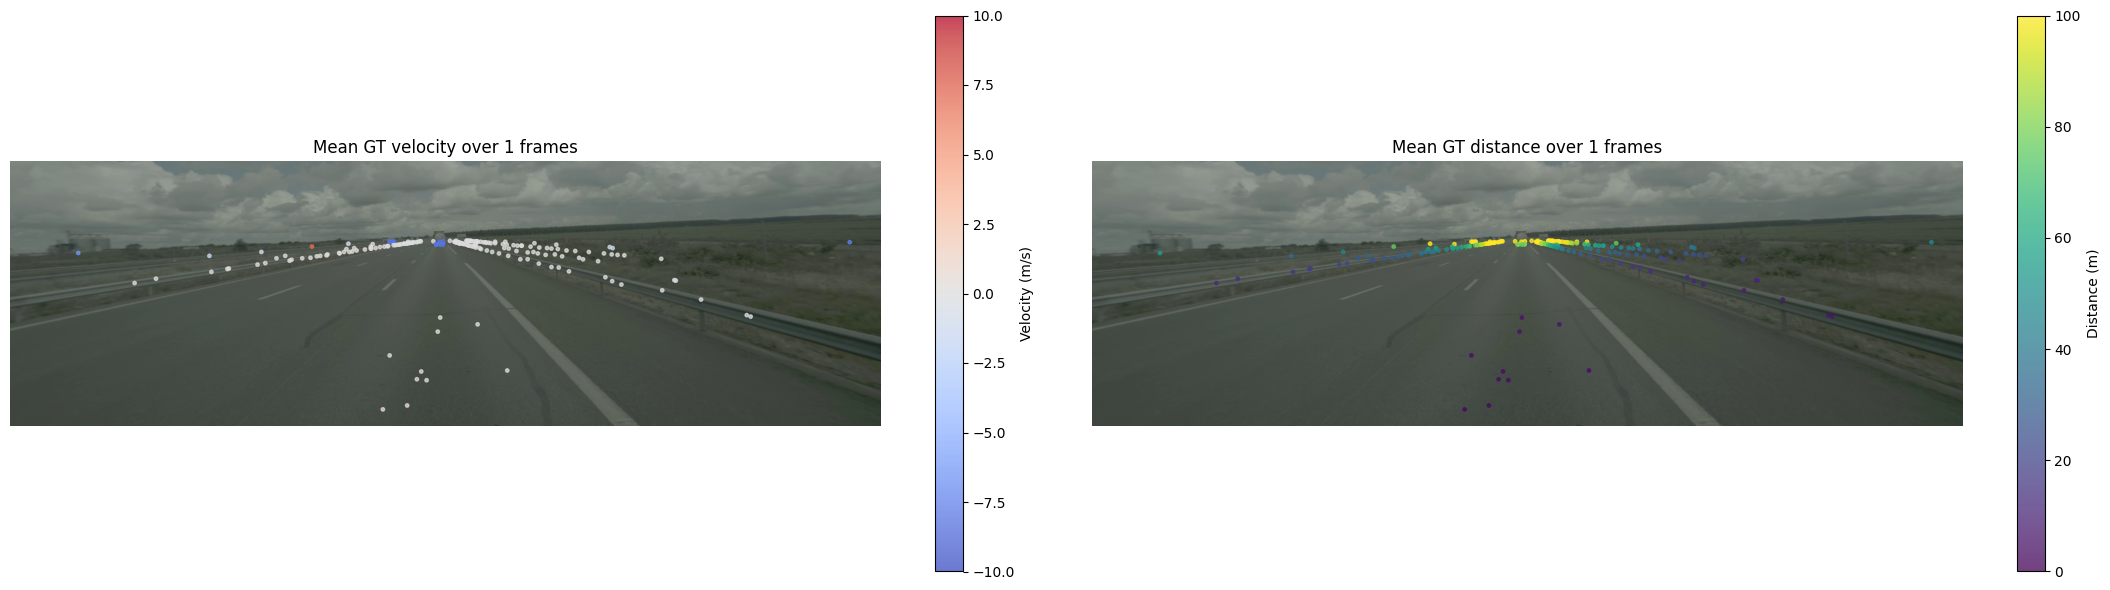

In [64]:
img = res["img"]  # uint8 HWC

# --- extract points ---
mask = np.isfinite(mean_vel) & (mean_vel != 0)
ys, xs = np.where(mask)

vel_vals = mean_vel[ys, xs]
depth_vals = mean_depth[ys, xs]

fig, axs = plt.subplots(1, 2, figsize=(22, 6))

# =====================================================
# Velocity plot
# =====================================================
axs[0].imshow(img)

sc_vel = axs[0].scatter(
    xs,
    ys,
    c=vel_vals,
    cmap="coolwarm",
    vmin=-10,
    vmax=10,
    s=6,          # dot size
    alpha=0.75,
)

axs[0].set_title(f"Mean GT velocity over {num_frames} frames")
axs[0].axis("off")
plt.colorbar(sc_vel, ax=axs[0], label="Velocity (m/s)")

# =====================================================
# Distance plot
# =====================================================
axs[1].imshow(img)

sc_dist = axs[1].scatter(
    xs,
    ys,
    c=depth_vals,
    cmap="viridis",
    vmin=0,
    vmax=100,     # adjust to radar range
    s=6,
    alpha=0.75,
)

axs[1].set_title(f"Mean GT distance over {num_frames} frames")
axs[1].axis("off")
plt.colorbar(sc_dist, ax=axs[1], label="Distance (m)")

plt.tight_layout()
plt.show()


### Determine normalization parameters

In [46]:
import numpy as np
from tqdm import tqdm

def compute_rgb_normalization_stats_streaming(
    dataset,
    pipeline,
    num_images: int = -1,
):
    """
    Compute global RGB mean/std over a subset of images.

    Args
    ----
    dataset      : MMSeg-style dataset
    pipeline     : preprocessing pipeline (must produce res["img"])
    num_images   :
        -1  -> use all images
         N  -> use N images, equally spaced over dataset

    Returns
    -------
    dict with rounded mean/std (3 decimals), uint8 scale [0,255]
    """

    total_images = len(dataset)

    if num_images == -1 or num_images >= total_images:
        indices = range(total_images)
    else:
        indices = np.linspace(
            0,
            total_images - 1,
            num_images,
            dtype=int,
        )

    rgb_sum = np.zeros(3, dtype=np.float64)
    rgb_sq_sum = np.zeros(3, dtype=np.float64)
    rgb_count = 0

    for i in tqdm(indices, desc="Computing RGB stats"):
        res = pipeline(dataset[i])
        img = res["img"].astype(np.float32)

        rgb_sum    += img.sum(axis=(0, 1))
        rgb_sq_sum += (img ** 2).sum(axis=(0, 1))
        rgb_count  += img.shape[0] * img.shape[1]

    rgb_mean = rgb_sum / rgb_count
    rgb_std  = np.sqrt(rgb_sq_sum / rgb_count - rgb_mean ** 2)

    return {
        "mean": [round(x, 3) for x in rgb_mean.tolist()],
        "std":  [round(x, 3) for x in rgb_std.tolist()],
        "num_images_used": len(indices),
    }

In [47]:
rgb_stats = compute_rgb_normalization_stats_streaming(
    dataset,
    pipeline,
    num_images=-1, # enter -1 for all images, enter num images to restrict
)


Computing RGB stats: 100%|██████████| 187/187 [01:20<00:00,  2.31it/s]


In [48]:
rgb_stats

{'mean': [80.182, 87.428, 79.65],
 'std': [25.751, 25.934, 27.112],
 'num_images_used': 187}